# 03 · Feature Engineering, Naive Bayes Math & Feature Selection

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.float_format", "{:,.3f}".format)
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)


In [2]:
master = pd.read_parquet(ROOT / "data/processed/master_orders.parquet")
dlv = master[master.is_delivered == 1].copy()          # delivered orders (used for most analyses)
print(f"all orders: {len(master):,} | delivered: {len(dlv):,}")


all orders: 98,500 | delivered: 96,305


In [3]:
from src.features import TASKS, feature_columns, modeling_frame, build_preprocessor, SKEWED
for t, cfg in TASKS.items():
    print(f"{t:13s} target={cfg['target']:11s} numeric={len(cfg['numeric'])} categorical={len(cfg['categorical'])}")

late          target=is_late     numeric=19 categorical=4
satisfaction  target=bad_review  numeric=25 categorical=4


## 1. Engineered features
| Group | Features | Idea |
|---|---|---|
| Time | purchase month, weekday, hour, is_weekend | seasonality & workload |
| Promise | `estimated_delivery_days`, `shipping_limit_days`, `approval_hours` | how much slack the promise has |
| Basket | n_items, n_sellers, total_price, total_freight, **freight_ratio**, weight, volume | heavy/multi-seller orders are harder |
| Geography | customer_state, seller_state, **same_state**, **distance_km (haversine)** | logistics difficulty |
| Payment | payment_type, installments | boleto needs bank confirmation → slower |
| Seller history | **seller_prior_late_rate**, **seller_prior_bad_rate**, seller_prior_orders | seller reliability, computed only from the past |
| Delivery outcome (satisfaction only) | actual_delivery_days, **delay_days**, is_late | what the customer experienced |

**Leakage rule.** The *late* model may only use information available at checkout. The *satisfaction* model is used after delivery, so the actual delivery outcome is allowed — but the review itself, its text, and anything after the review never are.

## 2. Naive Bayes — the theory
**Bayes' theorem** for class $C$ given features $\mathbf{x} = (x_1, \dots, x_n)$:

$$P(C\mid\mathbf{x}) = \frac{P(\mathbf{x}\mid C)\,P(C)}{P(\mathbf{x})}$$

**Naive assumption:** features are conditionally independent given the class:

$$P(\mathbf{x}\mid C) = \prod_{j=1}^{n} P(x_j \mid C) \quad\Rightarrow\quad \hat{C} = \arg\max_{C}\; P(C)\prod_{j} P(x_j\mid C)$$

$P(\mathbf{x})$ is the same for every class, so it is only needed to normalise probabilities: $P(\mathbf{x}) = \sum_{C} P(C)\prod_j P(x_j\mid C)$.

**Categorical NB with Laplace smoothing** (α = 1) — avoids zero probabilities for unseen values:

$$P(x_j = v \mid C) = \frac{N_{C,j,v} + \alpha}{N_C + \alpha K_j}$$

where $K_j$ is the number of possible values of feature $j$.

**Gaussian NB** (used for continuous features in the model comparison):

$$P(x_j\mid C) = \frac{1}{\sqrt{2\pi\sigma_{C,j}^2}}\exp\!\left(-\frac{(x_j-\mu_{C,j})^2}{2\sigma_{C,j}^2}\right)$$

In practice we sum **log-probabilities** to avoid numerical underflow.

## 3. Worked example by hand: will this customer leave a bad review?
Features: `is_late` (0/1), `payment_type` (4 values), `same_state` (0/1). Target: `bad_review`.

In [4]:
toy = dlv[["is_late", "payment_type", "same_state", "bad_review"]].dropna().astype({"is_late": int, "bad_review": int})
feats = ["is_late", "payment_type", "same_state"]
alpha = 1.0
N = len(toy)
prior = toy.bad_review.value_counts().sort_index() / N
print("Priors P(C):", prior.round(4).to_dict())

query = {"is_late": 1, "payment_type": "boleto", "same_state": 0}
print("Query order:", query)

rows, log_post = [], {}
for c in [0, 1]:
    sub = toy[toy.bad_review == c]; Nc = len(sub)
    lp = np.log(prior[c])
    for f in feats:
        K = toy[f].nunique()
        count = (sub[f] == query[f]).sum()
        p = (count + alpha) / (Nc + alpha * K)
        rows.append({"class": c, "feature": f, "value": query[f], "count N_cjv": count, "N_c": Nc, "K_j": K, "P(x_j|C)": p})
        lp += np.log(p)
    log_post[c] = lp
display(pd.DataFrame(rows))

unnorm = {c: np.exp(v) for c, v in log_post.items()}
evidence = sum(unnorm.values())
post = {c: v / evidence for c, v in unnorm.items()}
print("Unnormalised  P(C)·ΠP(x|C):", {c: f"{v:.6f}" for c, v in unnorm.items()})
print("Evidence P(x)             :", f"{evidence:.6f}")
print("Posterior P(bad_review=1|x) by hand =", round(post[1], 6))

Priors P(C): {0: 0.7892, 1: 0.2108}
Query order: {'is_late': 1, 'payment_type': 'boleto', 'same_state': 0}


,class,feature,value,count N_cjv,N_c,K_j,P(x_j|C)
0,0,is_late,1,1703,75494,2,0.023
1,0,payment_type,boleto,15026,75494,4,0.199
2,0,same_state,0,47310,75494,2,0.627
3,1,is_late,1,4675,20165,2,0.232
4,1,payment_type,boleto,4033,20165,4,0.200
5,1,same_state,0,13918,20165,2,0.690


Unnormalised  P(C)·ΠP(x|C): {0: '0.002222', 1: '0.006747'}
Evidence P(x)             : 0.008969
Posterior P(bad_review=1|x) by hand = 0.752279


In [5]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
enc = OrdinalEncoder()
Xtoy = enc.fit_transform(toy[feats].astype(str))
cnb = CategoricalNB(alpha=1.0).fit(Xtoy, toy.bad_review)
q = enc.transform(pd.DataFrame([query]).astype(str))
p_sklearn = cnb.predict_proba(q)[0, 1]
print(f"scikit-learn CategoricalNB  P(bad_review=1|x) = {p_sklearn:.6f}")
print("Hand calculation matches scikit-learn:", np.isclose(p_sklearn, post[1]))

scikit-learn CategoricalNB  P(bad_review=1|x) = 0.752279
Hand calculation matches scikit-learn: True


The hand computation and `CategoricalNB` agree exactly. A late order paid by boleto from another state has a much higher bad-review probability than the base rate (~22%).

**Limitation:** the independence assumption is violated (e.g. `same_state` and `is_late` are correlated), so NB probabilities are over-confident — which is why we also train discriminative models (Logistic Regression, tree ensembles) in notebook 04.

In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
cv = StratifiedKFold(3, shuffle=True, random_state=42)
for task in TASKS:
    X, y, _ = modeling_frame(master, task)
    pipe = Pipeline([("prep", build_preprocessor(task)), ("nb", GaussianNB())])
    s = cross_val_score(pipe, X, y, cv=cv, scoring="roc_auc")
    print(f"Gaussian NB on all features — {task:12s} ROC-AUC {s.mean():.3f} ± {s.std():.3f}")

Gaussian NB on all features — late         ROC-AUC 0.647 ± 0.009


Gaussian NB on all features — satisfaction ROC-AUC 0.681 ± 0.004


## 4. Feature selection
We run several families of methods on the **satisfaction** task and the **late** task and look for consensus:

* **Filter** — variance threshold, correlation & VIF (multicollinearity), ANOVA F-test, χ² test / Cramér's V for categoricals, mutual information.
* **Wrapper** — Recursive Feature Elimination (RFE) with logistic regression.
* **Embedded** — L1 (Lasso) logistic regression, Random-Forest impurity importance.

In [7]:
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from scipy import stats

def numeric_matrix(task, n=25000):
    X, y, _ = modeling_frame(master, task)
    idx = X.sample(min(n, len(X)), random_state=42).index
    num = TASKS[task]["numeric"]
    Xn = X.loc[idx, num].copy()
    for c in num:
        if c in SKEWED: Xn[c] = np.log1p(Xn[c].clip(lower=0))
    return Xn, y.loc[idx], X.loc[idx]

Xn, y, Xall = numeric_matrix("satisfaction")
vt = VarianceThreshold(1e-4).fit(Xn)
print("Near-constant features removed by VarianceThreshold:", list(Xn.columns[~vt.get_support()]) or "none")

Near-constant features removed by VarianceThreshold: none


In [8]:
# Correlation + VIF  (VIF_i = i-th diagonal element of the inverse correlation matrix)
R = Xn.corr()
vif = pd.Series(np.diag(np.linalg.pinv(R.values)), index=R.columns, name="VIF").sort_values(ascending=False)
high_pairs = [(a, b, round(R.loc[a, b], 3)) for i, a in enumerate(R.columns) for b in R.columns[i+1:] if abs(R.loc[a, b]) > 0.8]
print("Pairs with |r| > 0.8:", high_pairs)
vif.to_frame().head(10)

Pairs with |r| > 0.8: []


,VIF
delay_days,"57,313,120,308,013.375"
actual_delivery_days,"50,269,545,873,365.344"
estimated_delivery_days,"43,448,928,790,568.664"
total_price,12.679
freight_ratio,9.967
total_freight,6.402
total_weight_g,3.153
distance_km,2.813
is_weekend,2.548
purchase_weekday,2.482


`delay_days = actual_delivery_days − estimated_delivery_days` is a linear combination → huge VIF (perfect multicollinearity). Tree models don't care, but for linear models regularisation (L2/L1) handles it. `n_items`/`total_weight` and `is_weekend`/`weekday` are also related — expected by construction.

In [9]:
def selection_table(task):
    Xn, y, Xall = numeric_matrix(task)
    Z = (Xn - Xn.mean()) / Xn.std()
    F, pF = f_classif(Z, y)
    mi = mutual_info_classif(Z, y, random_state=42)
    l1 = LogisticRegression(penalty="l1", solver="liblinear", C=0.01, class_weight="balanced").fit(Z, y)
    rfe = RFE(LogisticRegression(max_iter=2000, class_weight="balanced"), n_features_to_select=10).fit(Z, y)
    rf = RandomForestClassifier(200, max_depth=10, n_jobs=-1, random_state=42, class_weight="balanced").fit(Z, y)
    t = pd.DataFrame({"ANOVA_F": F, "p_value": pF, "mutual_info": mi, "L1_coef": np.abs(l1.coef_[0]),
                      "RFE_rank": rfe.ranking_, "RF_importance": rf.feature_importances_}, index=Xn.columns)
    votes = pd.DataFrame({
        "ANOVA": t.p_value < 1e-3,
        "MI": t.mutual_info >= t.mutual_info.median(),
        "L1": t.L1_coef > 0,
        "RFE": t.RFE_rank == 1,
        "RF": t.RF_importance >= t.RF_importance.median()})
    t["votes (of 5)"] = votes.sum(axis=1)
    return t.sort_values(["votes (of 5)", "mutual_info"], ascending=False)

sel_sat = selection_table("satisfaction"); sel_sat

,ANOVA_F,p_value,mutual_info,L1_coef,RFE_rank,RF_importance,votes (of 5)
delay_days,"1,430.940",0.000,0.056,0.007,1,0.197,5
is_late,"3,355.887",0.000,0.048,0.427,1,0.116,5
actual_delivery_days,"2,365.240",0.000,0.043,0.396,1,0.170,5
n_items,372.296,0.000,0.009,0.254,1,0.078,5
seller_prior_bad_rate,397.486,0.000,0.008,0.233,1,0.062,5
estimated_delivery_days,60.154,0.000,0.004,0.000,1,0.030,4
n_sellers,330.633,0.000,0.002,0.172,1,0.027,4
distance_km,57.880,0.000,0.002,0.064,1,0.028,4
seller_prior_late_rate,114.441,0.000,0.001,0.040,1,0.024,4
total_price,38.901,0.000,0.009,0.000,1,0.021,3


In [10]:
sel_late = selection_table("late"); sel_late

,ANOVA_F,p_value,mutual_info,L1_coef,RFE_rank,RF_importance,votes (of 5)
purchase_month,25.412,0.000,0.014,0.083,1,0.170,5
total_freight,75.090,0.000,0.005,0.089,1,0.062,5
seller_prior_late_rate,326.658,0.000,0.004,0.337,1,0.117,5
distance_km,133.652,0.000,0.004,0.365,1,0.093,5
total_weight_g,26.679,0.000,0.004,0.056,1,0.041,4
n_sellers,17.442,0.000,0.004,0.183,1,0.003,4
same_state,132.919,0.000,0.004,0.341,1,0.032,4
estimated_delivery_days,19.849,0.000,0.002,0.634,1,0.121,4
product_volume_cm3,18.565,0.000,0.005,0.037,5,0.043,3
n_items,5.917,0.015,0.004,0.087,1,0.007,3


In [11]:
def cat_tests(task):
    X, y, _ = modeling_frame(master, task)
    out = []
    for c in TASKS[task]["categorical"]:
        ct = pd.crosstab(X[c], y); chi2, p, dof, _ = stats.chi2_contingency(ct)
        out.append({"feature": c, "chi2": chi2, "dof": dof, "p_value": p,
                    "cramers_v": np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))})
    return pd.DataFrame(out).set_index("feature").sort_values("cramers_v", ascending=False)
print("Satisfaction:"); display(cat_tests("satisfaction"))
print("Late delivery:"); display(cat_tests("late"))

Satisfaction:


,chi2,dof,p_value,cramers_v
feature,,,,
category,691.797,73,0.000,0.085
customer_state,605.059,26,0.000,0.080
seller_state,165.163,21,0.000,0.042
payment_type,8.731,3,0.033,0.010


Late delivery:


,chi2,dof,p_value,cramers_v
feature,,,,
customer_state,"1,791.706",26,0.000,0.137
seller_state,289.337,21,0.000,0.055
category,156.407,73,0.000,0.040
payment_type,17.451,3,0.001,0.013


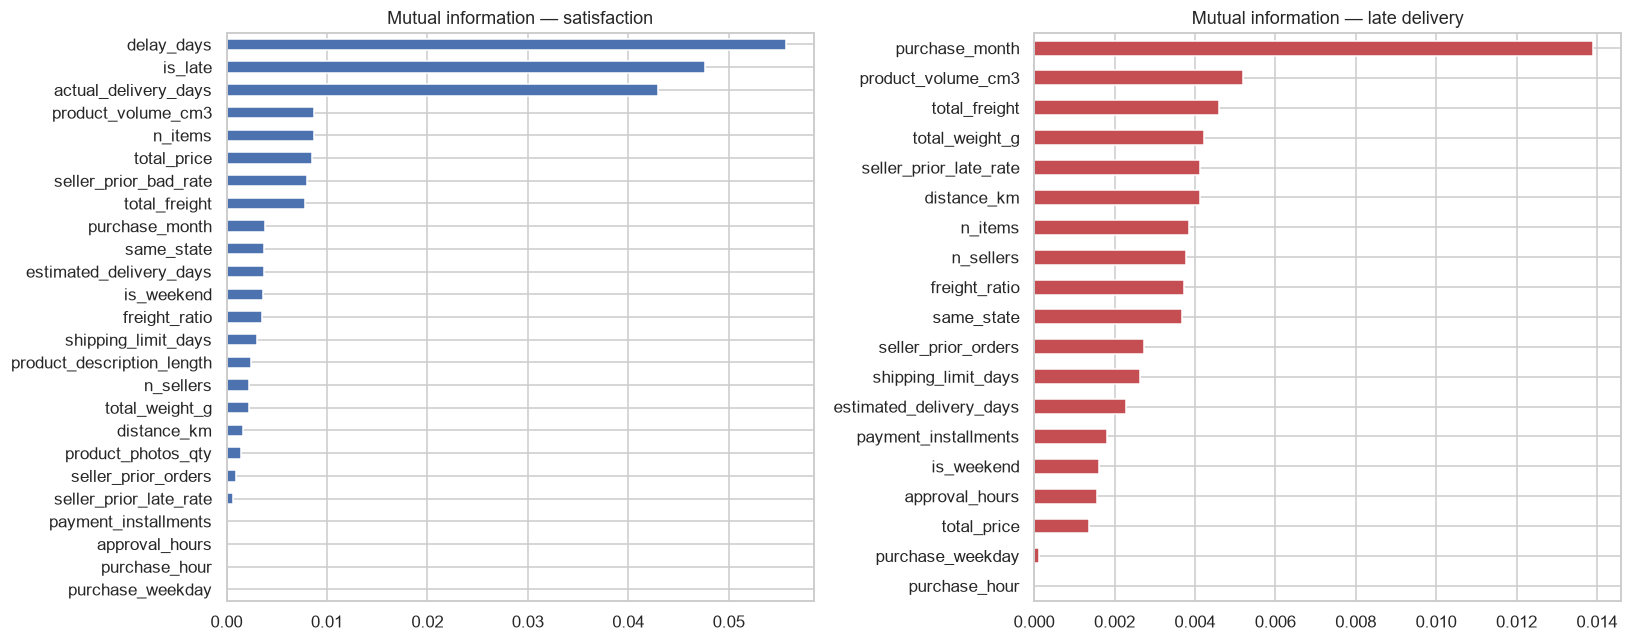

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sel_sat.mutual_info.sort_values().plot.barh(ax=axes[0], color="C0", title="Mutual information — satisfaction")
sel_late.mutual_info.sort_values().plot.barh(ax=axes[1], color="C3", title="Mutual information — late delivery")
plt.tight_layout(); plt.savefig(FIG / "feature_selection_mi.png"); plt.show()

### Selection decision
* **Satisfaction:** the delivery-outcome features (`delay_days`, `actual_delivery_days`, `is_late`) and `seller_prior_bad_rate` win every vote; basket size (`n_items`, `n_sellers`) also matters (multi-item orders often arrive split → complaints).
* **Late delivery:** `estimated_delivery_days`, `seller_prior_late_rate`, `distance_km`, `same_state`, purchase month (seasonality) and customer state carry the signal.
* Features with 0 votes are weak but cheap; tree ensembles are robust to them, so we **keep the full engineered set** for the gradient-boosting model and rely on regularisation (L2) for the linear model. The tables above are the evidence for the report.

Next: [04_modeling.ipynb](04_modeling.ipynb).